# Práctica 3.2: Clustering

<center><h3>
    Pablo Pardo Cotos
</h3></center>

## Instrucións

Isto é un **Jupyter Notebook**, un documento que integra código Python nun arquivo Markdown.
Isto permítenos, ir exexutando celdas de código pouco a pouco, así como xerar automáticamente un informe ben formateado da práctica.

Podes engadir unha celda co botón **"Insert"** da barra de ferramentas, e cambiar seu tipo con **"Cell > Cell Type"**

Para executar unha celda de código, seleccionarémola e pulsaremos a botón **"▶ Run"** da barra de ferramentas.
Para pasar o documento a HTML, seleccionaremos **"File > Download as > HTML (.html)"**

Segue este guión ata o final. Executa o código proporcionado paso a paso comprendendo o que estás a facer e reflexionando sobre os resultados. Haberá preguntas intercaladas ao longo do guión, responde a todas elas na sección reservada para ese fin: **"Respostas ao cuestionario"**. Por favor, non modifiques ningunha liña de código agás cando se che pida explícitamente.

Non esquezas insertar o teu **nome e apelidos** na celda superior.

## Entrega da práctica

A data límite de entrega será a indicada no Campus Virtual. A entrega consistirá nun único arquivo comprimido co nome `APELIDOS_NOME_Clustering.zip` que conteña os seguintes ficheiros:

 * `APELIDOS_NOME_Clustering.html`: Arquivo HTML froito da exportación do presente Notebook, coas preguntas respondidas ao final do documento.
 * `APELIDOS_NOME_Clustering.ipynb`: Arquivo Jupyter Notebook fonte.
 * Arquivo de datos do problema de libre elección.

## Números aleatorios

<span style="color:red">**MOI IMPORTANTE:**</span> Vamos a establecer un *seed* cun valor predefinido inmediatamente antes de executar calquera operación cun compoñente aleatorio. Así nos aseguraremos de que os nosos resultados sexan repetibles.

Isto é, imos poñer `np.random.seed(SEED_VALUE)` antes de:
 - `train_test_split()`
 - `fit()`
 - `predict()`
 
Tamén imos poñer `random_state=SEED_VALUE` en aquelas funcións que o admitan (coma o construtor de `KMeans`).

Haberá ocasión nas que isto sexa excesivo, pero así curámonos en despistes.

# Introdución

Nesta práctica imos reforzar os conceptos vistos nas clases teóricas sobre aprendizaxe non supervisada. Comezaremos traballando sobre un conxunto de datos xa coñecido, o da superficie e prezo das vivendas, sobre o cal aplicaremos o algoritmo **k-means**. O segundo exercicio consistirá en aplicar clustering a un problema de libre elección.

# Clustering sobre o dataset das vivendas

Na práctica anterior fomos capaces de dar un prezo estimado das vivendas a partir da súa superficie. Agora imos usar as dúas variables, superficie e prezo, para buscar novas relacións entre os nosos datos e facer unha distinción en varias categorías de vivendas.

Cargamos os datos empregando a función `read_csv()`:

In [1]:
import pandas as pd  # Importamos a librería (isto sólo é necesario facelo unha vez)

vivendas = pd.read_csv('vivendas.csv',  # Cargamos o csv
                       delimiter=',',
                       header=0)

Nesta práctica non vai ser preciso dividir os datos en dous conxuntos (adestramento e test), xa que o que queremos atopar son **novas** relacións. Isto implica tamén que non vai haber ningunha etapa de validación de modelos. En lugar diso, o que se adoita facer é unha etapa de análise e interpretación dos agrupamentos obtidos.

## Agrupamento empregando funcións propias

___K-means___ é un algoritmo de clasificación non supervisada (*clustering*) que agrupa os exemplos dun conxunto de datos en $k$ grupos baseándose nas súas características. O agrupamento realízase minimizando a suma de distancias (habitualmente distancia cadrática) entre cada exemplo e o centroide do grupo (*cluster*) ao que foi asignado. 

O algoritmo consta de 3 etapas diferenciadas:

1. **Inicialización**: unha vez escollido o número de grupos $k$, establécense aleatoriamente $k$ centroides no espazo de datos.
2. **Asignación dos exemplos aos centroides**: cada instancia do dataset é asignada ao seu centroide máis próximo.
3. **Actualización dos centroides**: para cada grupo, actualízase a posición do centroide tomando como novo centroide a posición media dos exemplos pertenecentes a dito grupo.
 
Os pasos 2 e 3 repítense durante $n$ iteracións. O algoritmo resolve un problema de optimización, sendo a función a optimizar (minimizar) a suma das distancias cadráticas de cada exemplo ao centroide do seu cluster.
 
Imos empregar as seguintes funcións:

In [2]:
import numpy as np

# Función de distancia cadrática
def calcula_distancias(a, b):
    matriz_distancias = np.empty([a.shape[0], b.shape[0]])
    # Calculamos a distancia punto a punto dos conxuntos a e b
    for i in range(a.shape[0]):
        for j in range(b.shape[0]):
            diff = a[i] - b[j]
            matriz_distancias[i, j] = np.sqrt(diff[0] ** 2 + diff[1] ** 2)
    
    return matriz_distancias

# Función a optimizar J
def j(x, centroides, clusters):
    # Obtemos a distancia de cada punto ao seu cluster
    distancias = x - centroides[clusters]
    # Calculamos o custo
    custo = 1.0/x.shape[0] * sum(np.sqrt(distancias[:, 0]**2 + distancias[:,1]**2))
    return custo

# Función de actualización de centroides
def actualiza_centr(x, clusters, centroides):
    for i in range(centroides.shape[0]):
        x_cluster_i = x[clusters==i]
        centroides[i] = np.sum(x_cluster_i, axis=0)/x_cluster_i.shape[0]
    
    return centroides

# Función de clustering k-means
def k_medias(x, centroides, iteracions):
    hist_clusters = []
    hist_centroides = []
    hist_custo = []
    
    for i in range(iteracions):
        dist_centroides = calcula_distancias(x, centroides)
        clusters = np.argmin(dist_centroides, axis=1)
        centroides = actualiza_centr(x, clusters, centroides)
        custo = j(x, centroides, clusters)
        # Gardamos o historial de cada iteración
        hist_clusters.append(clusters)
        hist_centroides.append(centroides.copy())
        hist_custo.append(custo)
    
    return {'custo': hist_custo, 'clusters': hist_clusters, 'centroides': hist_centroides}

Xa podemos realizar un primeiro agrupamento. Convertemos o dataset a unha matriz porque neste caso facilítanos as operacións:

In [3]:
vivendas_mat = vivendas.values

Tomamos 3 exemplos ao azar como centroides iniciais (non debemos esquecernos de definir unha semente para que os resultados sexan reptibles):

In [4]:
SEED_VALUE = 190463  # NON CAMBIES ESTE SEED, así todos teremos os mesmos resultados

np.random.seed(SEED_VALUE)
centroides_iniciais = vivendas_mat[np.random.choice(vivendas_mat.shape[0], size=3, replace=False)]
centroides_iniciais

array([[210.  , 299.9 ],
       [106.  , 104.96],
       [ 76.  ,  80.15]])

Invocamos o método `k_medias`:

In [5]:
# Definimos o número de iteracións do algoritmo
n_iter = 20
# Invocamos o método k_medias
agrupamento_1 = k_medias(vivendas_mat, centroides_iniciais, n_iter)

A variable `agrupamento_1` almacena o historial de custos, os centroides e as asignacións de cada exemplo aos 3 clusters en todas as iteracións. Aquí tes algúns exemplos da información á que podes acceder:

In [6]:
# Custo trala primeira iteración
agrupamento_1['custo'][0]

np.float64(44.57248682542861)

In [7]:
# Custo final
agrupamento_1['custo'][n_iter-1]

np.float64(39.661108023599255)

In [8]:
# Centroides na iteración 4
agrupamento_1['centroides'][3]

array([[208.57142857, 351.38357143],
       [126.61538462, 157.60307692],
       [ 93.87878788,  86.56242424]])

In [9]:
# Asignación dos 6 primeiros exemplos do dataset aos clusters na última iteración
agrupamento_1['clusters'][n_iter-1][:6]

array([2, 1, 1, 2, 1, 2])

Imos graficar paso a paso como foi converxendo o algoritmo para chegar ao agrupamento definitivo:

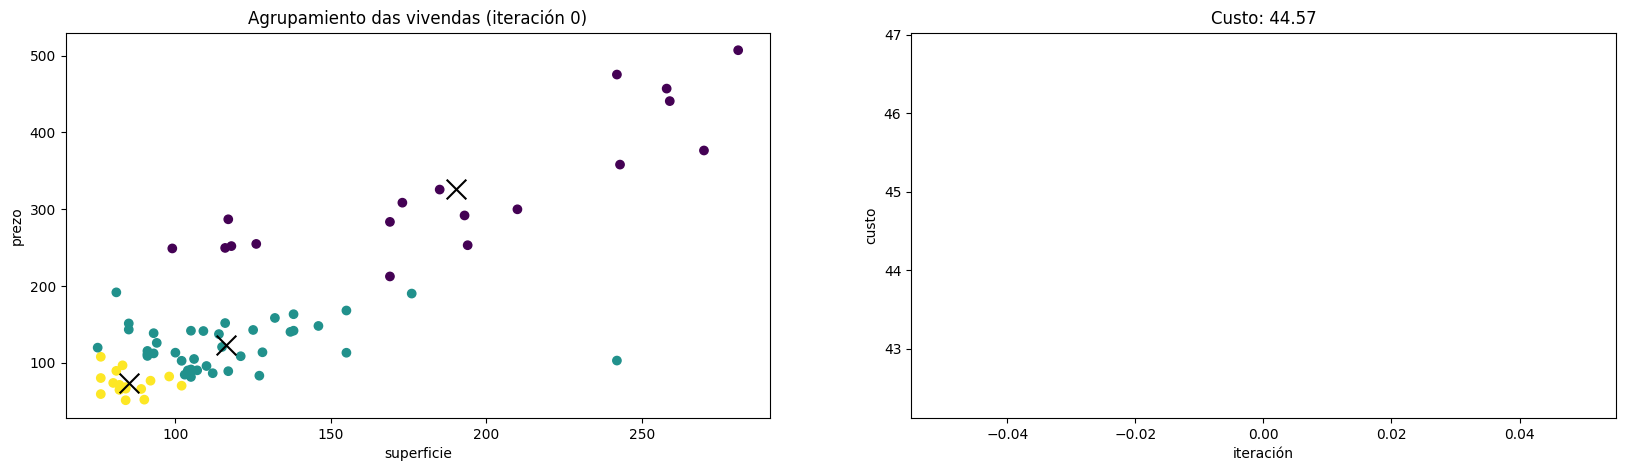

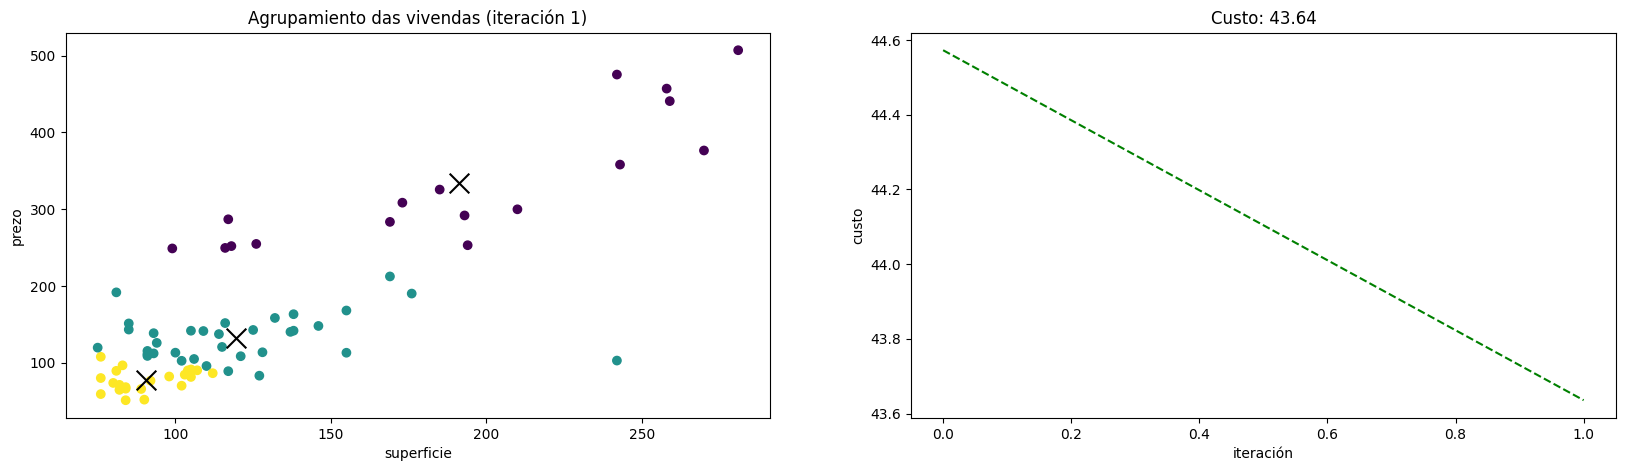

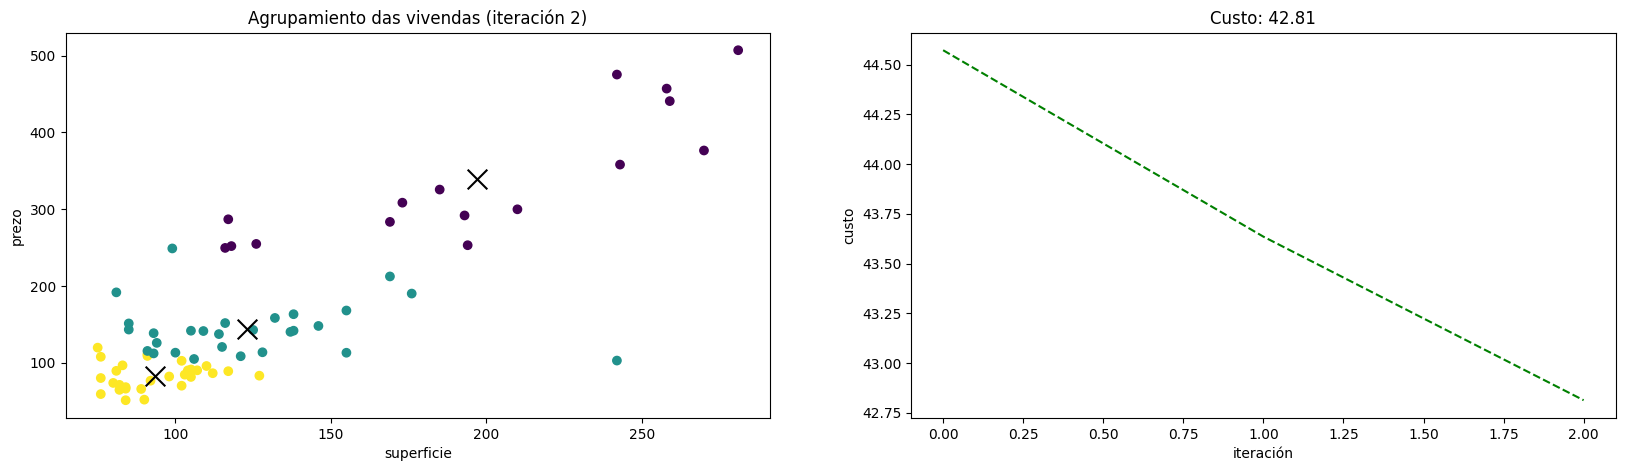

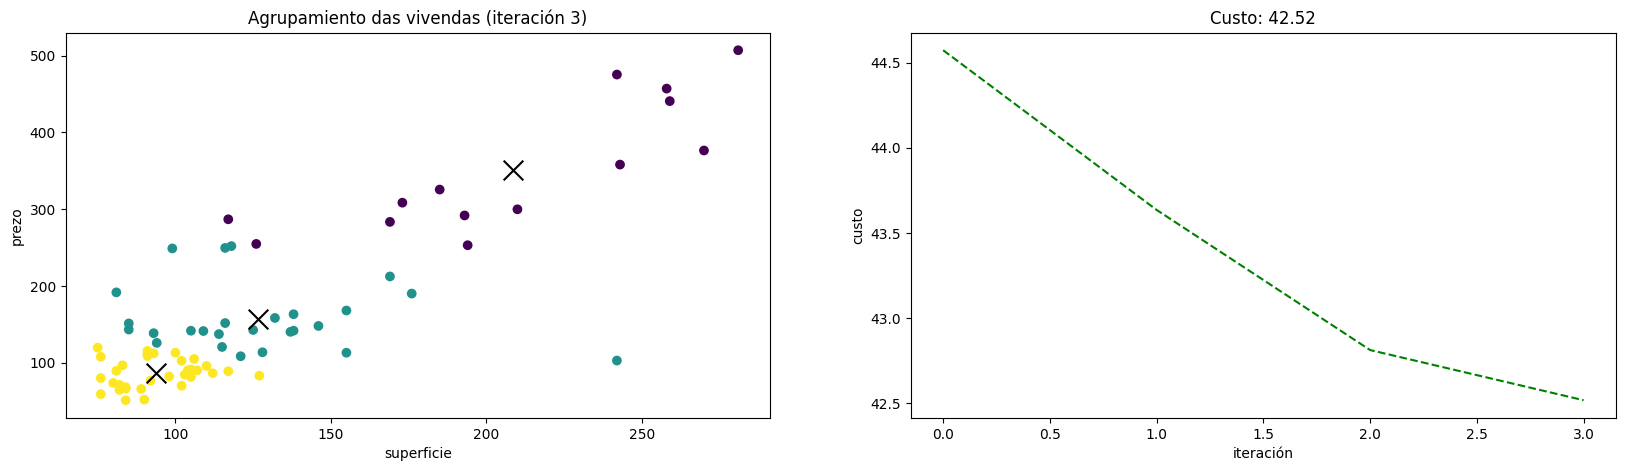

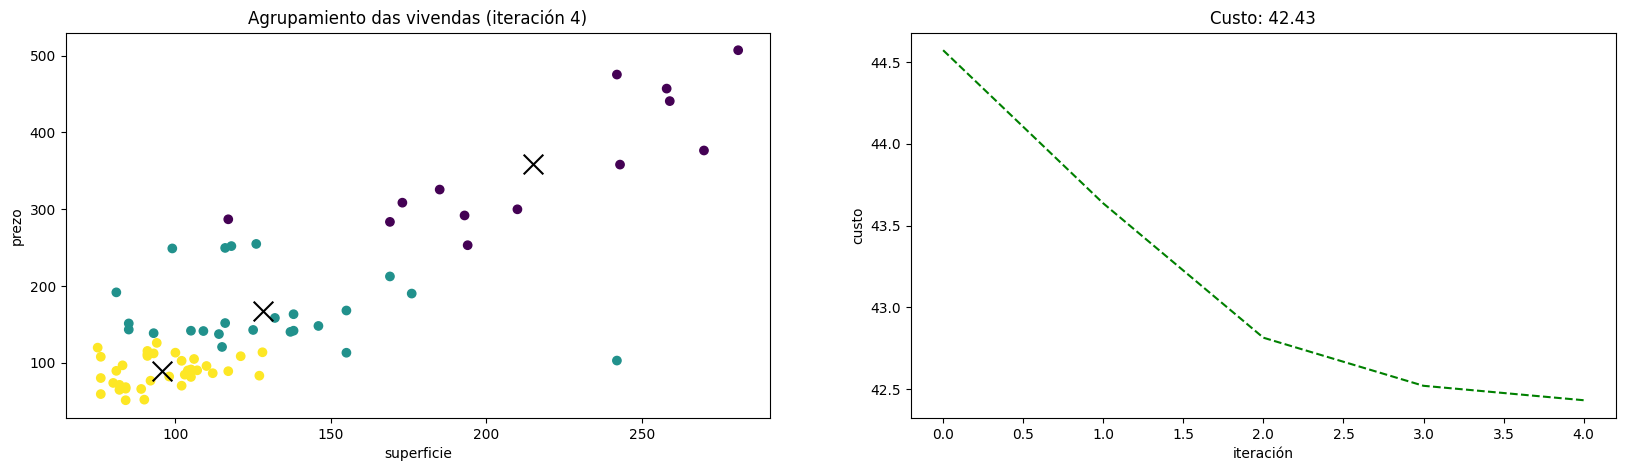

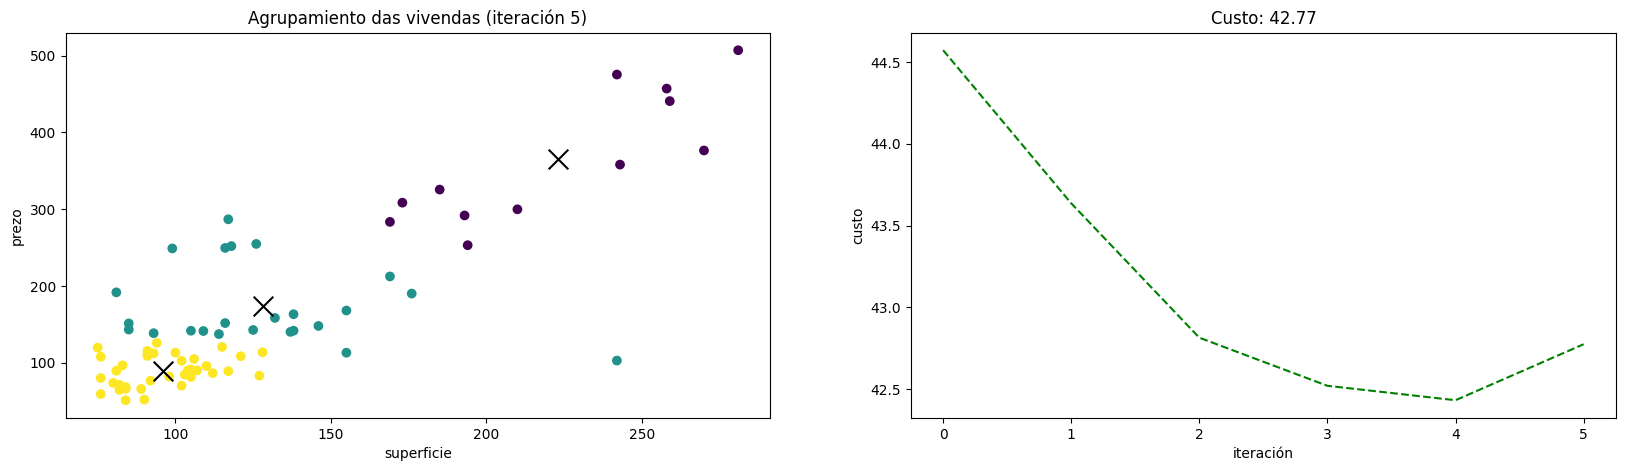

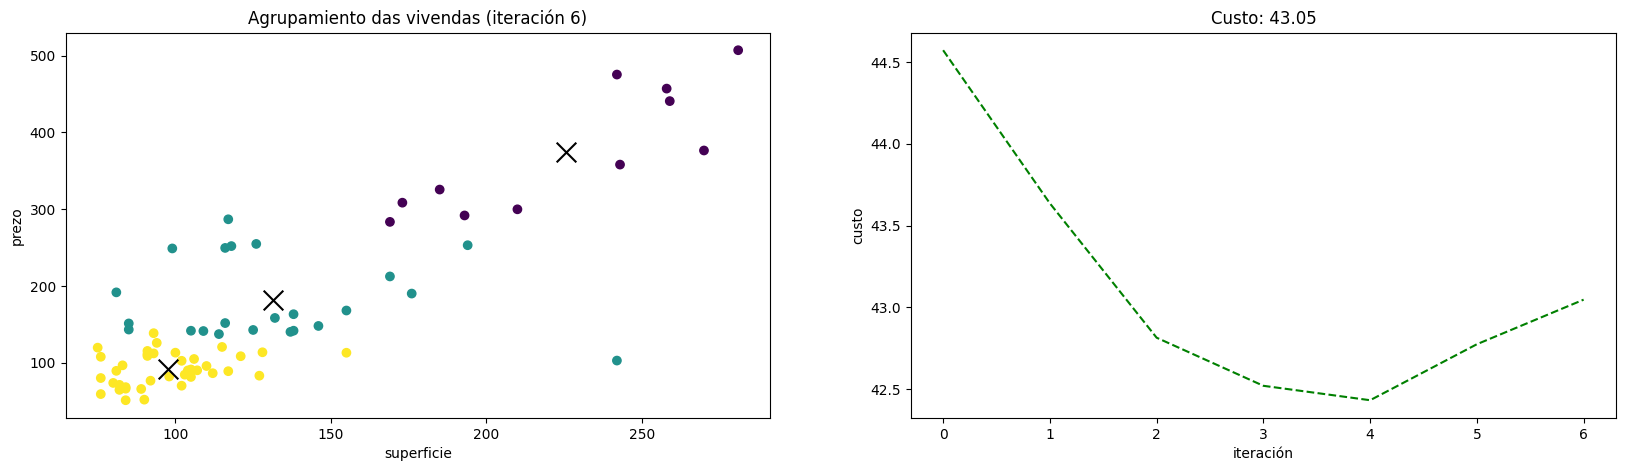

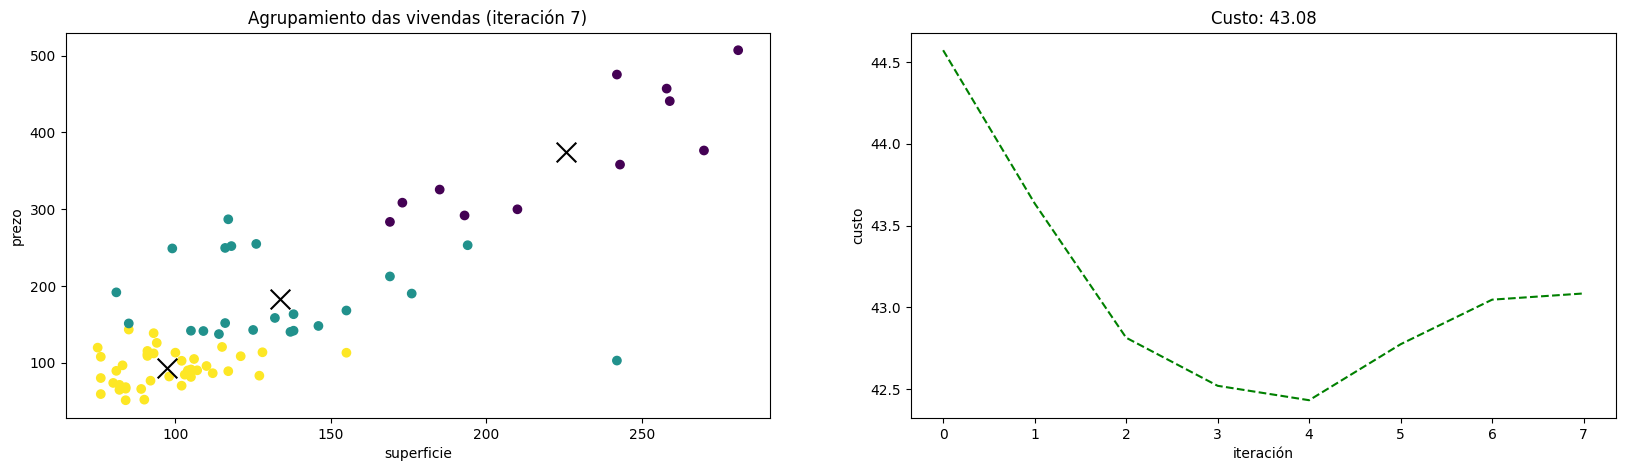

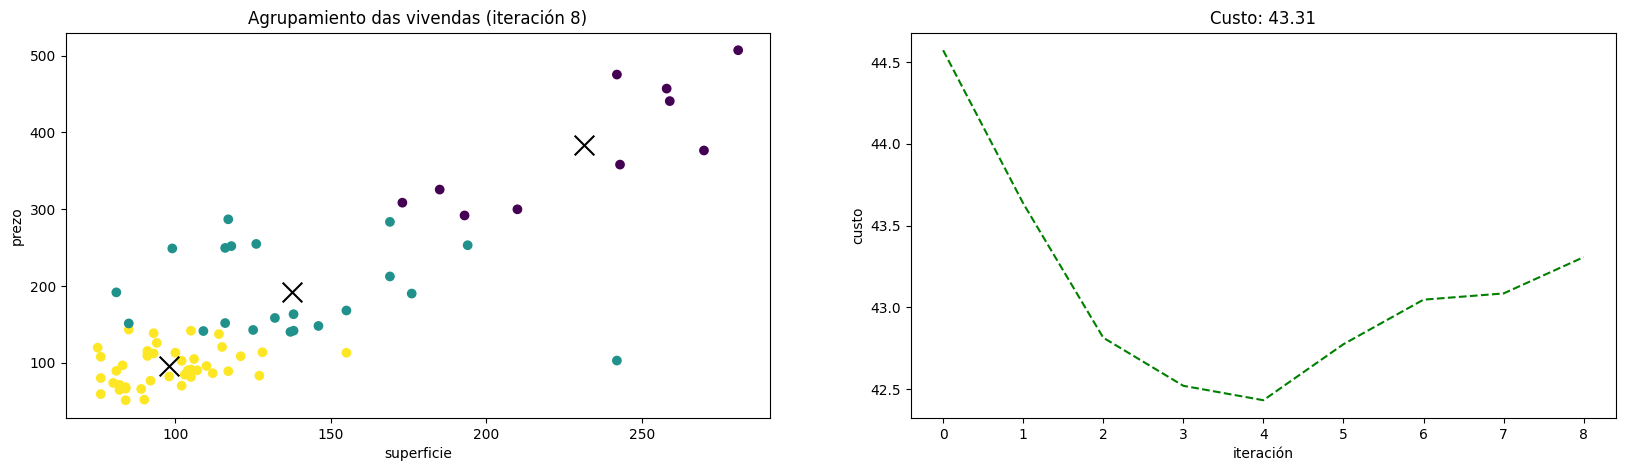

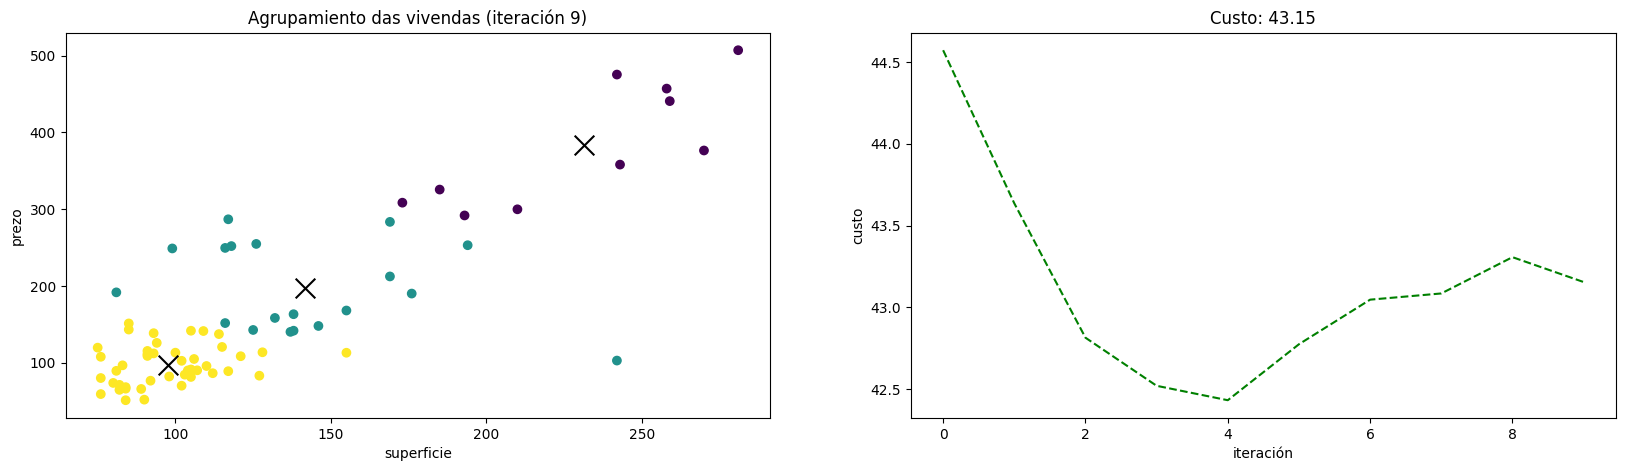

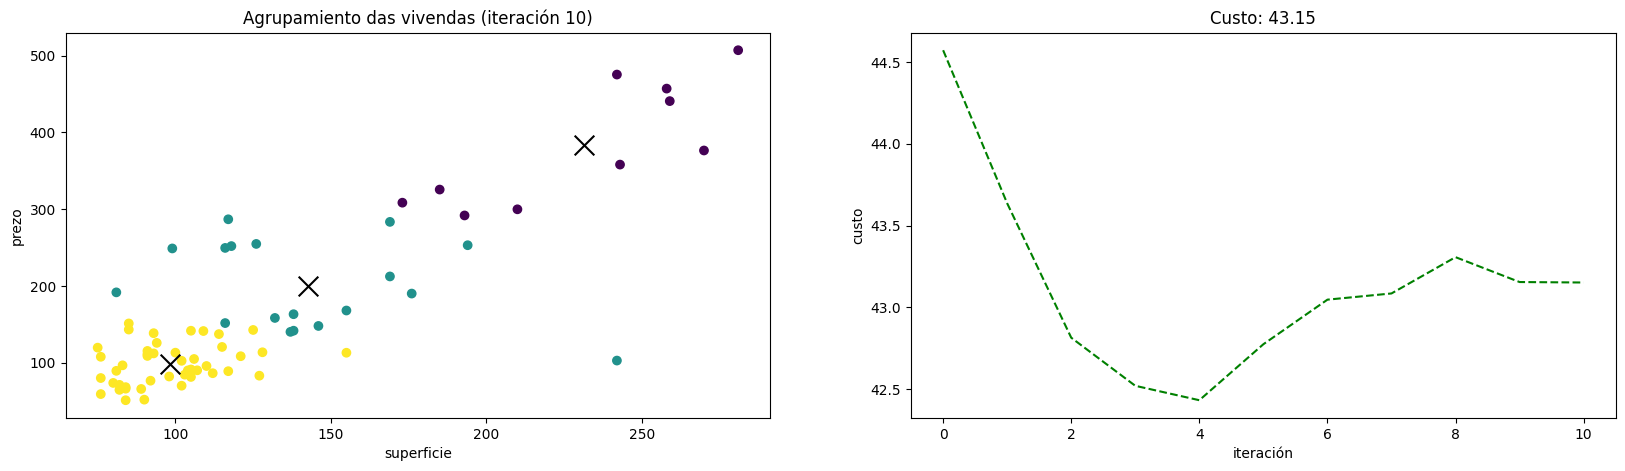

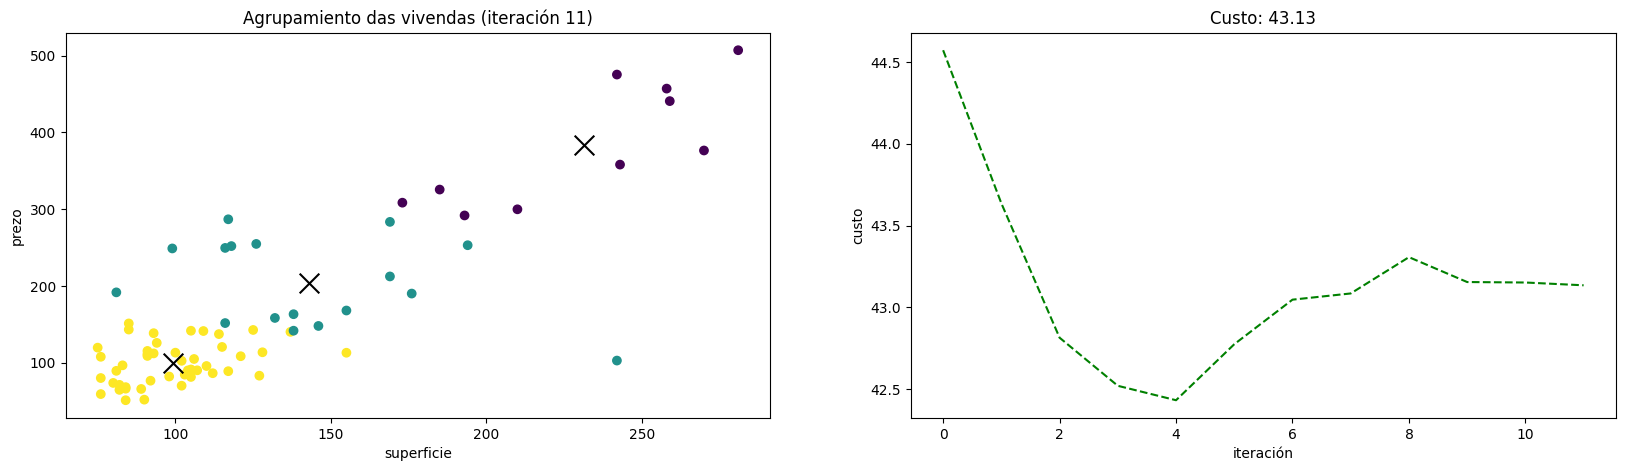

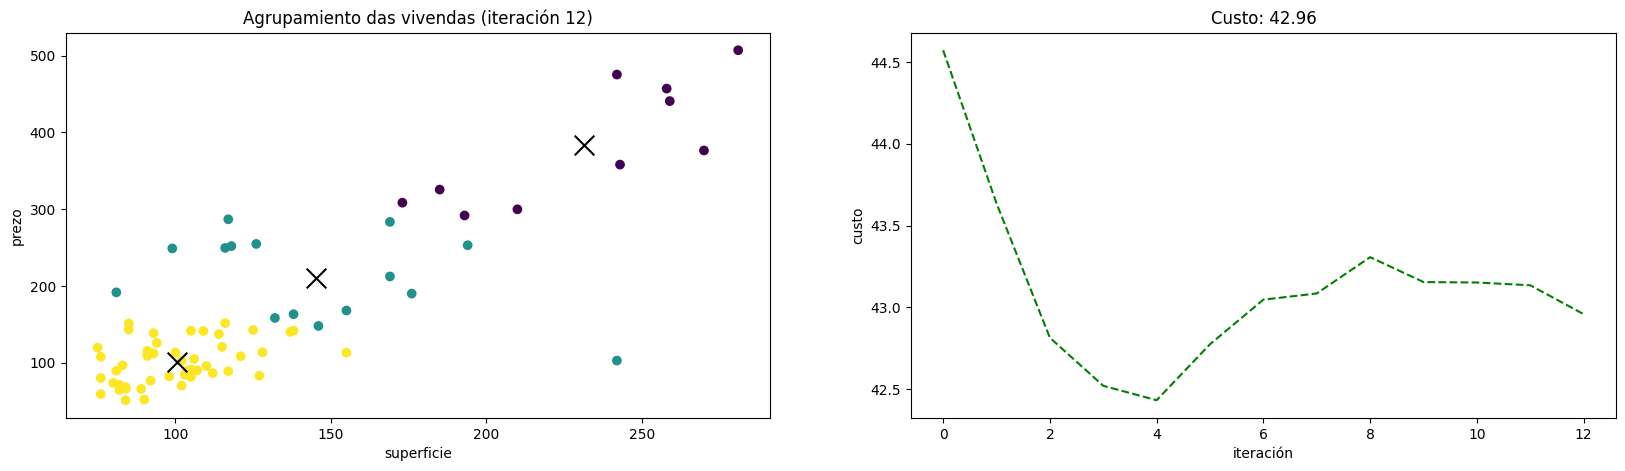

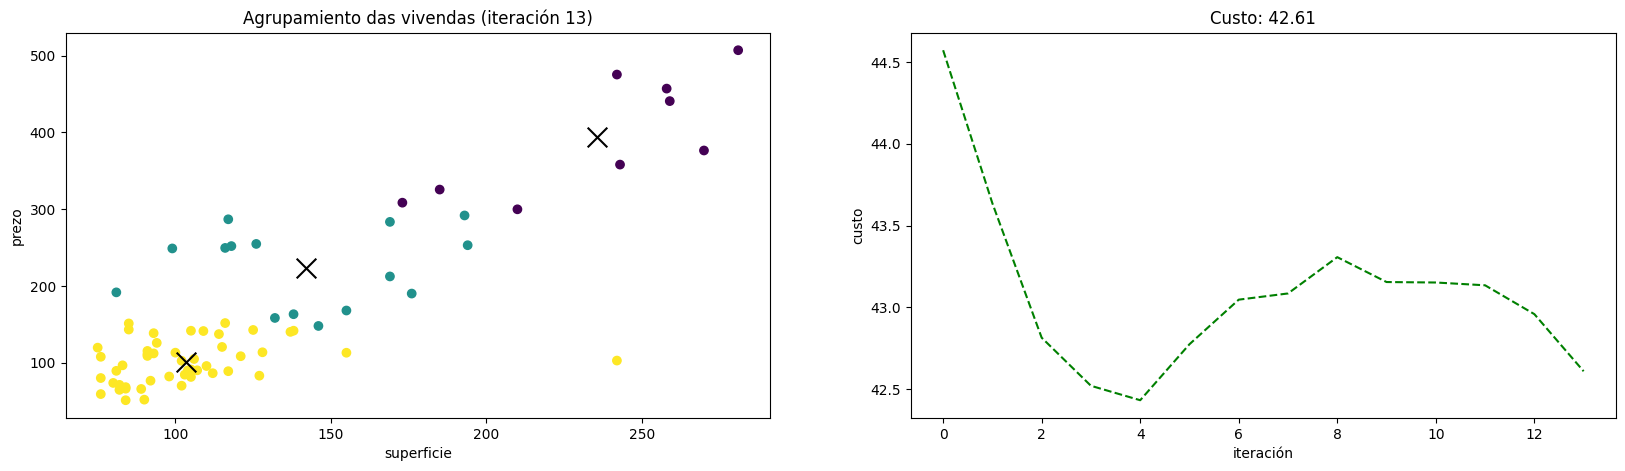

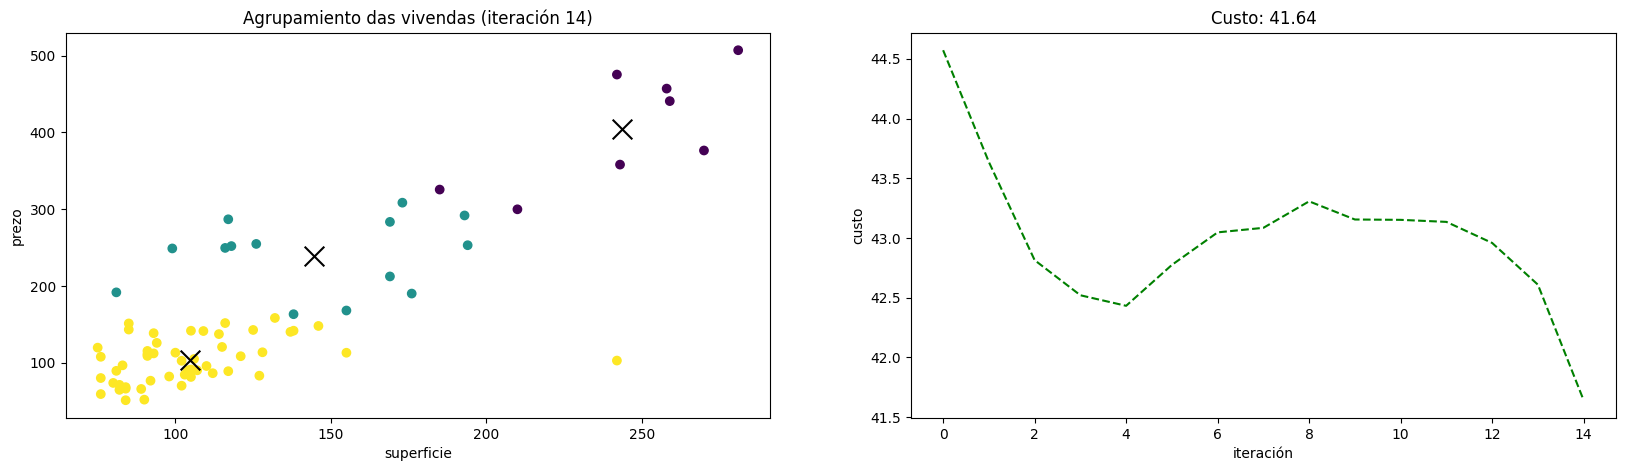

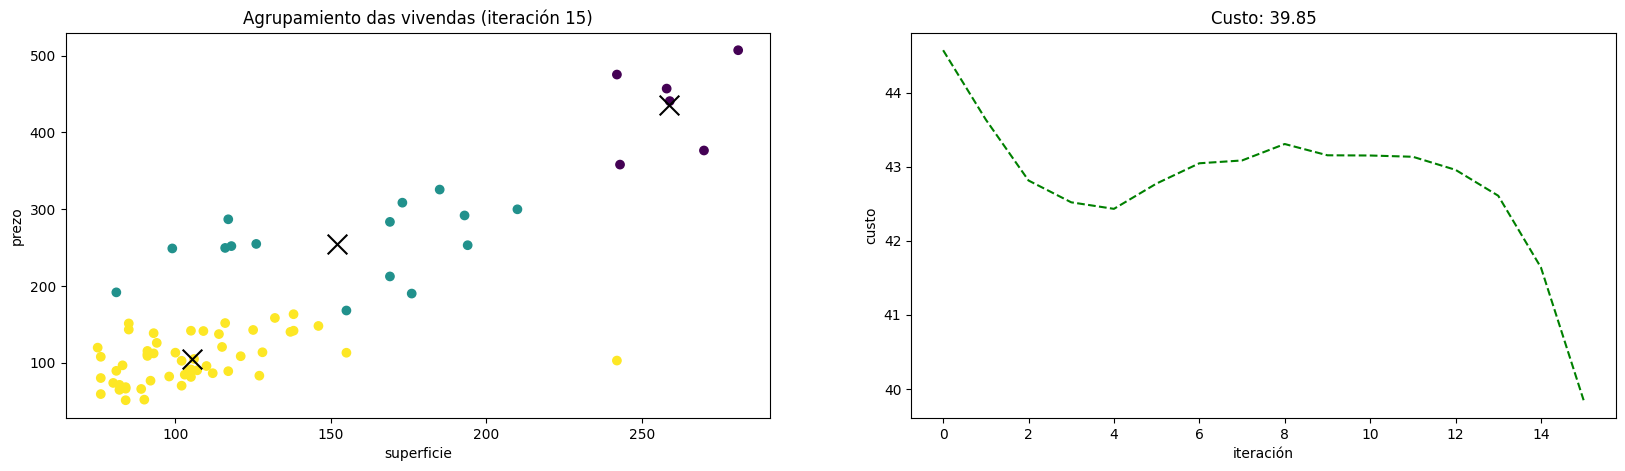

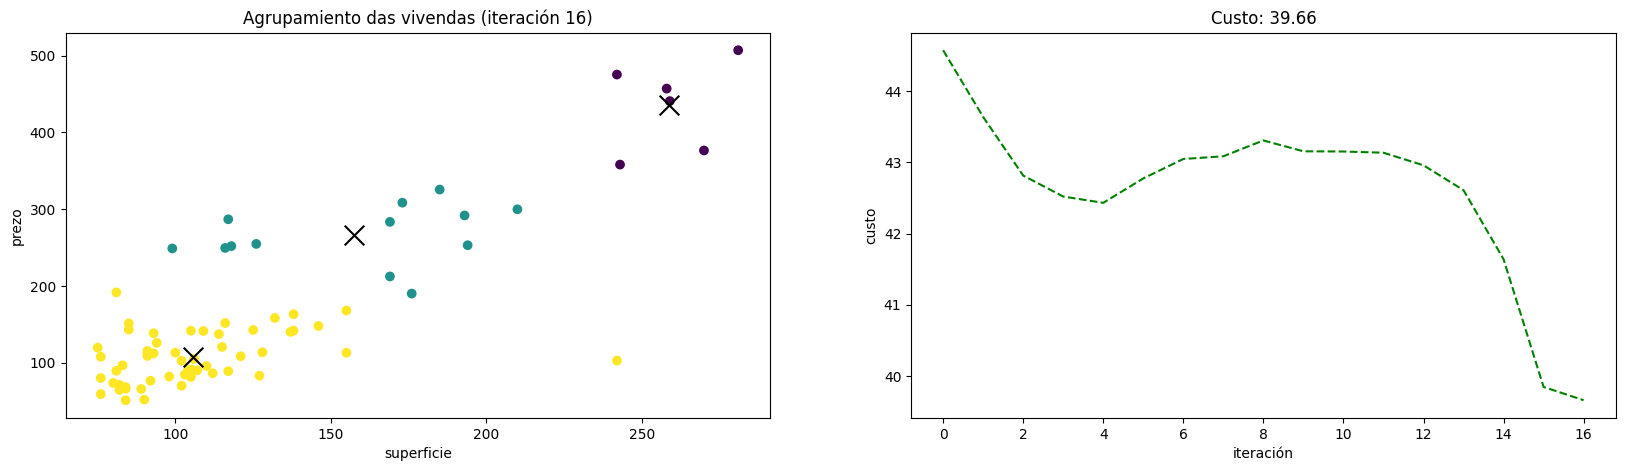

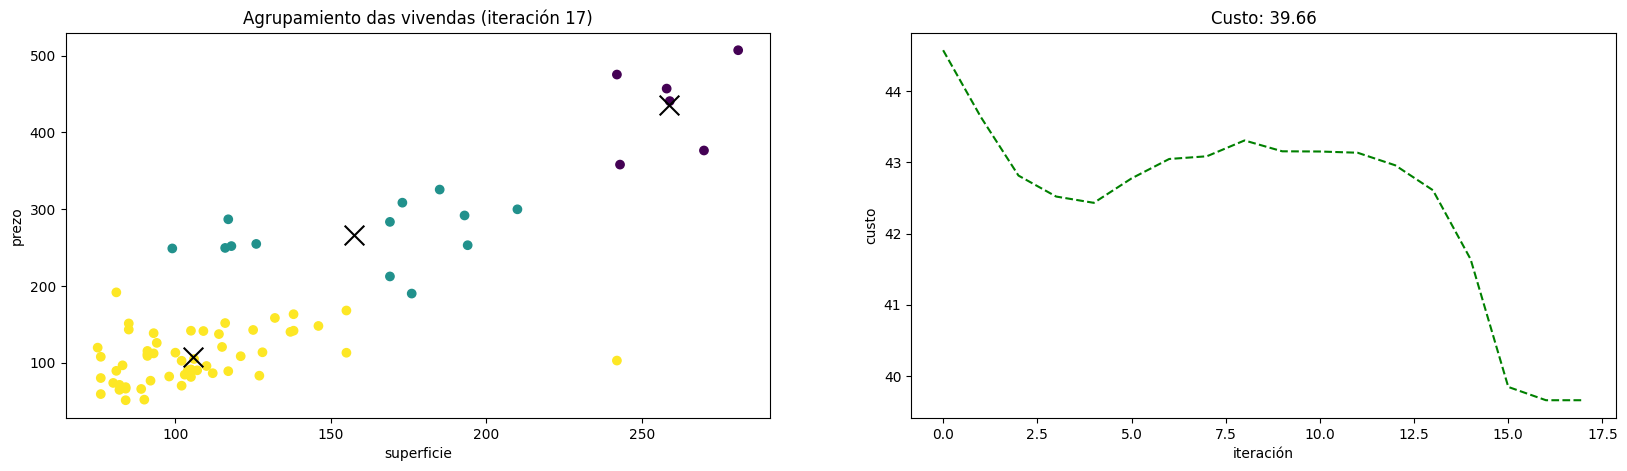

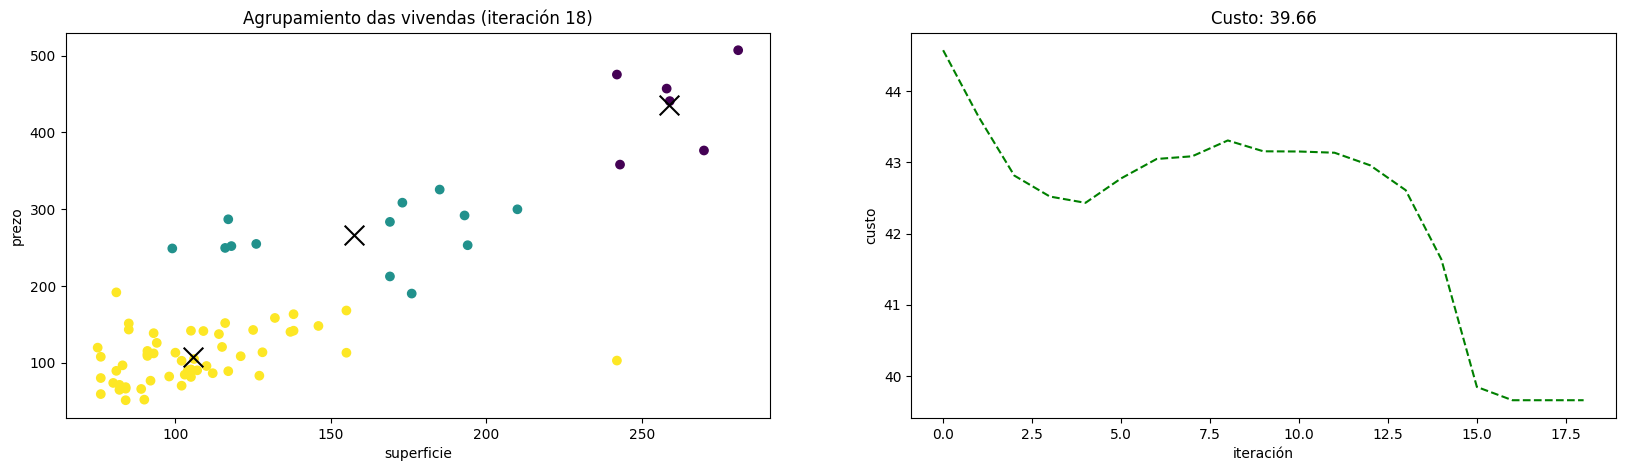

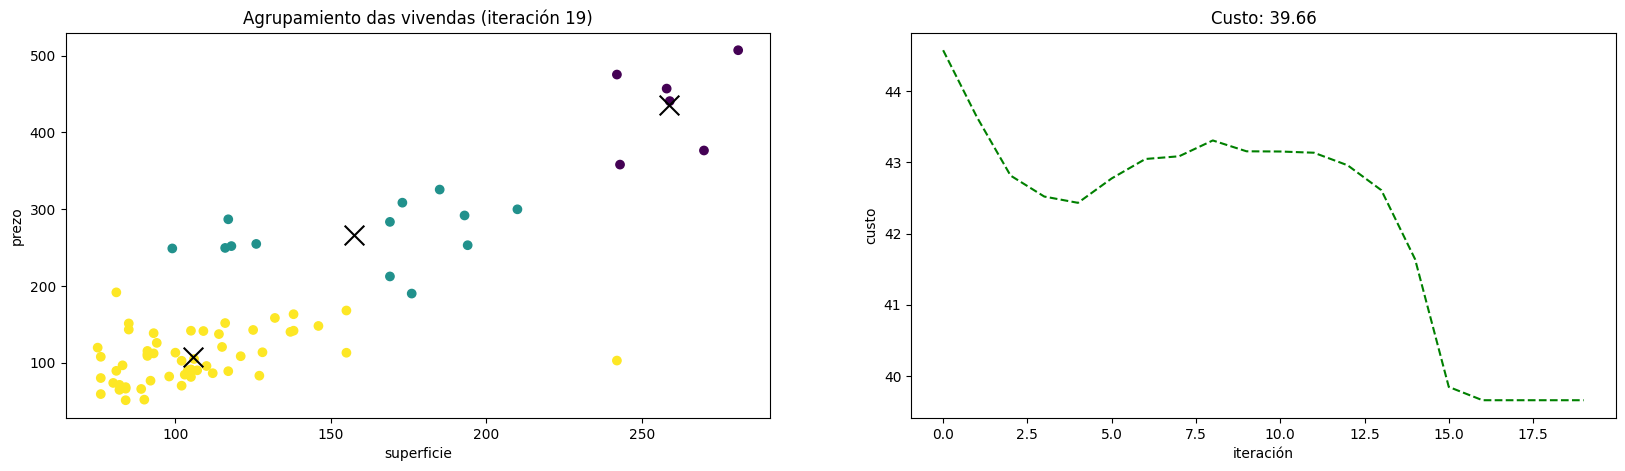

In [10]:
import matplotlib.pyplot as plt

for i in range(n_iter):
    fig = plt.figure(figsize=(20, 5))  # Creamos unha figura (contenedor para elementos a debuxar)
    ax1 = fig.add_subplot(121, projection='rectilinear')  # Engadimos Axes á figura (contén os elementos do debuxo, queremos unha matrix [1,2])
    ax2 = fig.add_subplot(122, projection='rectilinear')
    
    # Engadimos os scatterplots
    ax1.scatter(vivendas['superficie'], vivendas['prezo'], c=agrupamento_1['clusters'][i])  #Vivendas
    ax1.scatter(agrupamento_1['centroides'][i][:, 0], agrupamento_1['centroides'][i][:, 1],
                s=200, marker='x', color='black')  # Centroides
    ax1.set_title("Agrupamiento das vivendas (iteración {})".format(i))  # Poñemos un título
    ax1.set_xlabel("superficie")  # Nombramos os eixos
    ax1.set_ylabel("prezo")
    
    # Engadimos os custos
    ax2.plot(range(i+1), agrupamento_1['custo'][:i+1], '--', color="green")
    ax2.set_title("Custo: {:.2f}".format(agrupamento_1['custo'][i]))  # Poñemos un título
    ax2.set_xlabel("iteración")  # Nombramos os eixos
    ax2.set_ylabel("custo")


    plt.show()  # Mostramos a figura por pantalla

Nas figuras anteriores, a gráfica da esquerda indica sempre o agrupamento realizado. Os exemplos do conxunto de datos coloréanse de distinta cor en función do cluster ao que son asignados. As **x** cunha circunferencia arredor ubican os centroides. Na gráfica da dereita temos a evolución do custo ($J$) nas sucesivas iteracións, tal e como faciamos en regresión lineal.

Agora que viches o proceso de clustering paso a paso, trata de responder ás seguintes cuestións.

> ❓ **_Pregunta 1._**  Lembra que na práctica anterior o custo viña dado polo erro cadrático medio das diferenzas entre cada predición e o valor do prezo real. Como estimamos o custo no caso da aprendizaxe non supervisada con k-means?

> ❓ **_Pregunta 2._**  Explica que é a saída da función `calcula_distancias`.

> ❓ **_Pregunta 3._**  Explica que contén `x_cluster_i` e que é o que fai a expresión `np.sum(x_cluster_i, axis=0)/x_cluster_i.shape[0]` na función `actualiza_centr`.

> ❓ **_Pregunta 4._**  Identifica no código dos scripts anteriores onde se realizan cada unha das 3 etapas de k-means (inicialización, asignación dos datos aos clusters e actualización dos centroides).

### Inicialización aleatoria múltiple dos centroides

Se cambiamos os centroides iniciais, o algoritmo pode non converxer aos mesmos resultados.

In [11]:
SEED_VALUE = 22634  # NON CAMBIES ESTE SEED, así todos teremos os mesmos resultados

np.random.seed(SEED_VALUE)
centroides_iniciais_2 = vivendas_mat[np.random.choice(vivendas_mat.shape[0], size=3, replace=False)]
centroides_iniciais_2

array([[259.  , 440.83],
       [ 81.  ,  89.52],
       [126.  , 254.81]])

In [12]:
# Realizamos un novo agrupamento
agrupamento_2 = k_medias(vivendas_mat, centroides_iniciais_2, n_iter)

Neste caso, posto que o problema é pequeno e sinxelo, 20 iteracións son máis que suficientes para converxer ao agrupamento óptimo, sexan cales sexan os centroides de arranque:

In [13]:
# Centroides finais do primeiro agrupamento
agrupamento_1['centroides'][n_iter-1]

array([[258.83333333, 435.845     ],
       [157.30769231, 265.95846154],
       [105.77777778, 107.42740741]])

In [14]:
# Centroides finais do segundo agrupamento
agrupamento_2['centroides'][n_iter-1]

array([[258.83333333, 435.845     ],
       [105.77777778, 107.42740741],
       [157.30769231, 265.95846154]])

Fíxate que, aínda que en esencia os resultados son os mesmos que no primeiro agrupamento, os centroides 2 e 3 están intercambiados, polo que tecnicamente a solución á que chega o algoritmo é outra (e, porén, todo o proceso iterativo foi distinto).

En moitos problemas reais os resultados cambiarán moito en función de como inicialicemos os centroides. Incluso no problema das vivendas, se o número de iteracións é máis pequeno (por exemplo, 10), non sempre se acadará o óptimo global. Porén sóense realizar múltiples ($m$) inicializacións aleatorias dos centroides. A seguinte función é unha extensión da función base `k_medias` que permite executar o k-means para $m$ inicializacións distintas dos centroides e un valor $k$ constante:

In [15]:
# Función k-means de inicialización aleatoria múltiple
def k_medias_multi_ini(x, n, m, k):
    x_mat = x.values
    custos_finais = []
    centroides_finais = []
    clusters_finais = []
    for i in range(m):
        centr_iniciais = x_mat[np.random.choice(x_mat.shape[0], size=k, replace=False)]
        agrupamento = k_medias(x_mat, centr_iniciais, n)
        custos_finais.append(agrupamento['custo'][n-1])
        centroides_finais.append(agrupamento['centroides'][n-1])
        clusters_finais.append(agrupamento['clusters'][n-1])
    
    custo_minimo = min(custos_finais)
    indice_mellor = np.argmin(custos_finais)
    centroides_mellor = centroides_finais[indice_mellor]
    clusters_mellor = clusters_finais[indice_mellor]
    
    return {'custo_minimo': custo_minimo, 'mellor_iteracion': indice_mellor,
            'mellores_centroides': centroides_mellor, 'mellor_asignacion': clusters_mellor}

Imos probar a función anterior:

In [16]:
SEED_VALUE = 134  # NON CAMBIES ESTE SEED, así todos teremos os mesmos resultados
np.random.seed(SEED_VALUE)

m_ini = 10
n_iter = 15
k_cent = 3
agrupamento_3 = k_medias_multi_ini(x=vivendas, n=n_iter, m=m_ini, k=k_cent)

In [17]:
# Mellor iteración
agrupamento_3['mellor_iteracion']

np.int64(5)

In [18]:
# Mellores centroides
agrupamento_3['mellores_centroides']

array([[258.83333333, 435.845     ],
       [157.30769231, 265.95846154],
       [105.77777778, 107.42740741]])

In [19]:
# Asignación do mellor cluster para cada un dos 6 primeiros exemplos do dataset:
agrupamento_3['mellor_asignacion'][:6]

array([2, 1, 1, 2, 1, 2])

> ❓ **_Pregunta 5._**  Que devolve a saída da función `k_medias_multi_ini`? Como se elixen os mellores centroides?

### Selección do número de centroides

Polo de agora mantivemos o valor de $k$ constante, facendo sempre agrupamentos en 3 clusters. Unha pregunta que che podería xurdir a estas alturas é como saber cal é o número de centroides máis axeitado. A selección do $k$ óptimo é a miúdo ambigua, con interpretacións que dependen da forma e a escala da distribución de puntos no conxunto de datos. Aumentar o $k$ sen penalización sempre reducirá o valor do custo na agrupación resultante, ata o caso extremo de custo cero se cada punto dos datos se considera como o seu propio agrupamento (é decir, cando $k$ é igual ao número de exemplos do conxunto de datos). Intuitivamente, a elección óptima de $k$ acadará un equilibrio entre a compresión máxima dos datos utilizando un só cluster e a máxima precisión ao asignar cada instancia ao seu cluster propio. 

Cando o valor apropiado de $k$ non é evidente a partir do coñecemento previo das propiedades do conxunto de datos, existen métodos que nos axudan a tomar esta decisión. Un dos máis sinxelos é o **método do cóbado** (en inglés, *elbow method*), o cal analiza a redución do custo en función do número de clusters: debe elixirse aquel número de clusters tal que, ao agregar outro cluster máis non se acaden resultados moito mellores. Dun xeito máis formal, se se grafica o custo obtido en función de $k$, os primeiros agrupamentos terán un alto erro por agrupar moitos datos en poucos clusters, pero nalgún momento a ganancia marxinal caerá, provocando un "cóbado" no gráfico. O número de clusters fíxase a este punto, de ahí o nome do método. 

O seguinte script executa o método `k_medias_multi_ini` para distintos valores de $k$ (o mínimo é $k=2$):

In [20]:
SEED_VALUE = 42  # NON CAMBIES ESTE SEED, así todos teremos os mesmos resultados
np.random.seed(SEED_VALUE)

k_max = 10
m_ini = 10
n_iter = 20
custos_finais = []
centroides_finais = []
clusters_finais = []
for k in range(2, k_max+1):
    agrupamento = k_medias_multi_ini(x=vivendas, n=n_iter, m=m_ini, k=k)
    custos_finais.append(agrupamento['custo_minimo'])
    centroides_finais.append(agrupamento['mellores_centroides'])
    clusters_finais.append(agrupamento['mellor_asignacion'])

> ❓ **_Pregunta 6._**  Cantas veces se executa o algoritmo k-means no script anterior?

Agora imos aplicar o método do cóbado para determinar o número óptimo de clusters. Para iso, graficamos a evolución do custo en función de $k$:

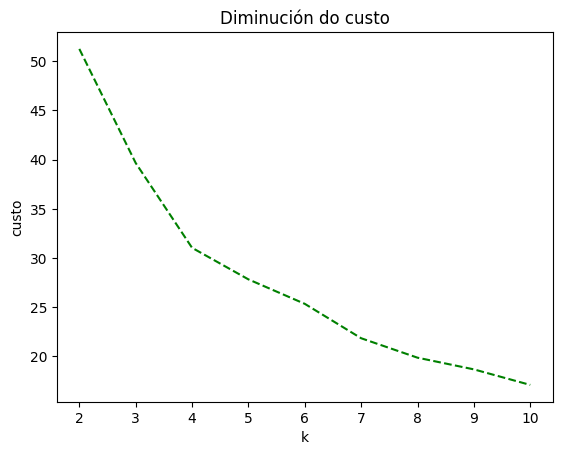

In [21]:
plt.plot(range(2, k_max+1), custos_finais, '--', color="green")
plt.title("Diminución do custo") 
plt.xlabel("k")
plt.ylabel("custo")
plt.show()

A simple vista pódese apreciar que o "cóbado" da función está en $k=4$. A partir deste valor a mellora que obtemos é moito menos significativa. Por tanto podemos asumir que o número de clusters ideal é 4:

In [22]:
k_mellor = 4

# Centroides para o mellor k (4)
centroides_mellor = centroides_finais[k_mellor-2]  # Hai que ter en conta que a lista comeza en 2
centroides_mellor

array([[ 93.87878788,  86.56242424],
       [126.81818182, 142.48545455],
       [155.75      , 272.275     ],
       [258.83333333, 435.845     ]])

In [23]:
# Asignación do mellor cluster para cada un dos 6 primeiros exemplos do dataset
clusters_mellor = clusters_finais[k_mellor-2]  # Hai que ter en conta que a lista comeza en 2
clusters_mellor[:6]

array([1, 2, 2, 1, 2, 0])

Graficamos o último agrupamento, que imos considerar o definitivo:

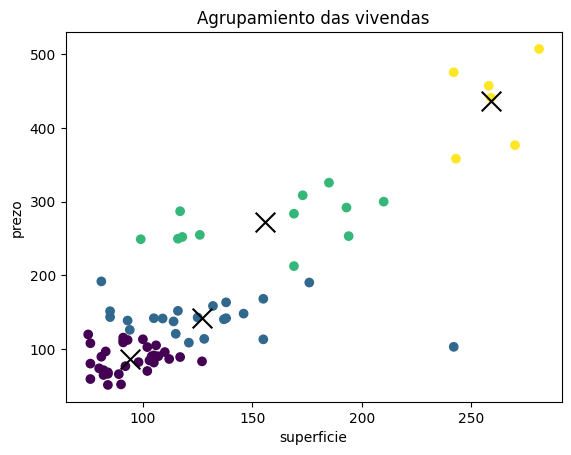

In [24]:
fig = plt.figure()  # Creamos unha figura (contenedor para elementos a debuxar)
ax1 = fig.add_subplot(111, projection='rectilinear')  # Engadimos Axes á figura (contén os elementos do debuxo)

# Engadimos os scatterplots
ax1.scatter(vivendas['superficie'], vivendas['prezo'], c=clusters_mellor)  #Vivendas
ax1.scatter(centroides_mellor[:, 0], centroides_mellor[:, 1], s=200, marker='x', color='black')  # Centroides

ax1.set_title("Agrupamiento das vivendas")  # Poñemos un título
ax1.set_xlabel("superficie")  # Nombramos os eixos
ax1.set_ylabel("prezo")

plt.show()  # Mostramos a figura por pantalla

### Interpretación dos resultados

Quedaría agora unha última etapa de análise e interpretación dos resultados. Haberá situacións (coma esta) onde a interpretación sexa bastante trivial. Sen embargo, en moitos problemas reais onde se traballa cun maior número de variables (porén, xa non estamos falando de interpretar un simple gráfico 2D) pode resultar moi complexo lograr atribuírlle un significado aos grupos formados.

> ❓ **_Pregunta 7._**  Fai unha breve interpretación dos clusters obtidos.

## Agrupamento coa función `KMeans`

Unha vez máis, `scikit-learn` facilítanos as tarefas de clustering proporcionándonos paquetes e funcións moi útiles. Unha das funcións imprescindibles é `KMeans`. No seguinte script imos volver a obter o primeiro dos agrupamentos que realizamos no exercicio anterior, pero invocando a `KMeans` en lugar de `k_medias`:

In [25]:
from sklearn.cluster import KMeans

# Definimos o número de iteracións
n_iter = 20

# Obtemos os mesmos centroides iniciais que antes
SEED_VALUE = 190463  # NON CAMBIES ESTE SEED, así todos teremos os mesmos resultados
np.random.seed(SEED_VALUE)
centr_iniciais = vivendas_mat[np.random.choice(vivendas_mat.shape[0], size=3, replace=False)]

# Definimos o modelo
# NOTA: algorithm='lloyd' foi eliminado en scikit-learn 1.3; 'lloyd' é o novo nome do mesmo algoritmo.
model = KMeans(n_clusters=len(centr_iniciais), init=centr_iniciais, n_init=1,
               max_iter=n_iter, algorithm='lloyd', random_state=SEED_VALUE)

# Axustamos o modelo aos datos
np.random.seed(SEED_VALUE)
agrupamento_4 = model.fit(vivendas)

O argumento `algorithm="full"` simplemente nos asegura que por debaixo estamos empregando o mesmo método que o que implementamos no exercicio anterior (hai varias implementacións, podes consultalas na axuda de `scikit-learn`). Vemos que os centroides que obtemos con `KMeans` son os mesmos que obtiñamos antes coa nosa implementación propia:

In [26]:
# Centroides da implementación propia
agrupamento_1['centroides'][-1]

array([[258.83333333, 435.845     ],
       [157.30769231, 265.95846154],
       [105.77777778, 107.42740741]])

In [27]:
# Centroides obtidos coa función KMeans
agrupamento_4.cluster_centers_

array([[258.83333333, 435.845     ],
       [157.30769231, 265.95846154],
       [105.77777778, 107.42740741]])

Bótalle un ollo aos atributos que contén a clase `KMeans`. Observa que entre todos os datos de saída non se inclúe directamente o custo da función $J$ coa que estivemos traballando. Inclúese a suma de todas as distancias, sen facer a media:

In [28]:
# Custo final coa implementación propia
agrupamento_1['custo'][-1]

np.float64(39.661108023599255)

In [29]:
# Custo final coa función KMeans
agrupamento_4.inertia_ / len(vivendas)

2072.6093651192286

Tamén podemos facer o cálculo manualmente, usando a función $J$ que temos definida:

In [30]:
j(x=vivendas_mat, centroides=agrupamento_4.cluster_centers_, clusters=agrupamento_4.labels_)

np.float64(39.66110802359926)

**************************************************************

# Respostas ao cuestionario

**LEMBRA:** Non esquezas de escribir teu nome e apelidos na segunda celda do presente documento.

**Pregunta 1**

En regresión lineal el coste comparaba cada predicción con el valor real (el error cuadrático medio). En k-means no hay valor real con el que comparar, porque los datos no tienen etiqueta. Por eso el coste mide lo cerca que está cada punto del centroide de su grupo: es la **distancia media de cada ejemplo a su centroide** (función `j`). Cuanto más pequeño, más compactos son los grupos. Este coste baja en cada iteración hasta que el algoritmo converge.

**Pregunta 2**

La función `calcula_distancias(a, b)` devuelve una **matriz con la distancia de cada punto de `a` a cada punto de `b`**, es decir, todas las combinaciones. Su tamaño es (nº de puntos de `a`) × (nº de puntos de `b`), y la casilla `[i, j]` es la distancia del punto `i` de `a` al punto `j` de `b`.

En `k_medias` se llama como `calcula_distancias(x, centroides)`, así que devuelve una matriz de 73 × 3: una fila por vivienda y una columna por centroide. Después, `np.argmin(..., axis=1)` elige en cada fila el centroide más cercano.

La distancia es la euclídea (aunque el comentario dice "cuadrática", al hacer `np.sqrt` no queda elevada al cuadrado), y solo usa las dos primeras columnas, por lo que solo sirve para datos de dos variables.

**Pregunta 3**

`x_cluster_i` contiene **las viviendas (filas de `x`) que pertenecen al cluster `i`**. Se obtiene con `x[clusters==i]`: `clusters==i` da un vector de True/False que indica qué viviendas están en el grupo `i`, y al usarlo como filtro solo se quedan esas filas (las demás no aparecen). Es una matriz con tantas filas como viviendas tiene el grupo y dos columnas (superficie y precio).

La expresión `np.sum(x_cluster_i, axis=0)/x_cluster_i.shape[0]` calcula **la media de esas viviendas**: `np.sum(..., axis=0)` suma por columnas (todas las superficies por un lado y todos los precios por otro) y `x_cluster_i.shape[0]` es el número de viviendas del grupo. El resultado es el **nuevo centroide** del cluster `i`, que se guarda en `centroides[i]`. Es el paso de actualización de los centroides de k-means.

**Pregunta 4**

Las 3 etapas están en estas partes del código:

1. **Inicialización**: en la celda de `SEED_VALUE = 190463`, con `vivendas_mat[np.random.choice(vivendas_mat.shape[0], size=3, replace=False)]`, que elige 3 viviendas al azar como `centroides_iniciais`. Después se le pasan a `k_medias(vivendas_mat, centroides_iniciais, n_iter)`.
2. **Asignación de los datos a los clusters**: dentro del bucle de `k_medias`, con `dist_centroides = calcula_distancias(x, centroides)` (distancia de cada vivienda a cada centroide) y `clusters = np.argmin(dist_centroides, axis=1)` (cada vivienda se asigna al centroide más cercano).
3. **Actualización de los centroides**: también dentro del bucle de `k_medias`, con `centroides = actualiza_centr(x, clusters, centroides)`, que mueve cada centroide a la media de las viviendas de su grupo.

Los pasos 2 y 3 se repiten `iteracions` veces gracias al bucle `for i in range(iteracions)` de `k_medias`.

**Pregunta 5**

`k_medias_multi_ini` ejecuta k-means `m` veces, cada una con unos centroides iniciales distintos elegidos al azar, y devuelve un diccionario con los datos de la mejor ejecución:

- `custo_minimo`: el coste final más bajo de todas las ejecuciones.
- `mellor_iteracion`: el índice de la ejecución que lo consiguió (aquí, la 5, es decir, la sexta, porque se empieza a contar en 0).
- `mellores_centroides`: los centroides finales de esa ejecución.
- `mellor_asignacion`: el cluster al que pertenece cada vivienda en esa ejecución.

Los mejores centroides se eligen comparando el **coste final** de cada ejecución: dentro del bucle se guarda el de todas en `custos_finais` y, al terminar, se toma la que tiene el **coste mínimo** (`np.argmin(custos_finais)`), porque es la que deja los puntos más cerca de sus centroides.

**Pregunta 6**

El script prueba los valores de $k$ de 2 a 10 (`for k in range(2, k_max+1)`), es decir, 9 valores. Para cada uno llama a `k_medias_multi_ini` con `m = m_ini = 10`, y esta función ejecuta k-means 10 veces, una por cada inicialización distinta de los centroides. En total, k-means se ejecuta **9 × 10 = 90 veces** (y cada ejecución hace `n_iter = 20` iteraciones).

**Pregunta 7**

Con $k=4$ las viviendas quedan separadas en cuatro gamas, en las que el precio y la superficie crecen juntos:

- **Viviendas económicas** (33 viviendas, con el centroide en unos 94 m² y 87 mil €): pequeñas y baratas, el grupo más numeroso.
- **Gama media** (22 viviendas, unos 127 m² y 143 mil €).
- **Gama alta** (12 viviendas, unos 156 m² y 272 mil €): no mucho más grandes que las de gama media, pero bastante más caras.
- **Viviendas de lujo** (6 viviendas, unos 259 m² y 436 mil €): las más grandes y caras, y el grupo más pequeño.

Los grupos se separan sobre todo por el precio, porque es la variable que más varía (los datos no están escalados). Por ejemplo, una vivienda de 242 m² que costó solo 103 mil € queda en la gama media.

**************************************************************

# Modelado dun problema real

## Enunciado

Pon en práctica os teus coñecementos de aprendizaxe non supervisado e intenta agora ti buscar relacións entre os datos dun problema real. En particular, imos traballar co dataset Heart Disease patients (https://www.kaggle.com/datasets/kingabzpro/heart-disease-patients), no que se fai referencias a distintas probas realizadas a pacientes con problemas cardíacos. Carga o ficheiro heart_disease_patients.csv e pon en práctica os teus coñecementos de agrupamento. Fai un breve estudo dos teus datos, incluíndo gráficas e comentarios propios. Realiza unha etapa de preprocesado, se o consideras necesario. Obtén un bo agrupamento dos pacientes, e da unha interpretación do mesmo. Lembra que non tés por que utilizar todas as variables incluídas no conxunto de datos. Ademais, podes probar a realizar distintos agrupamentos en subconxuntos do dataset inicial (por exemplo, agrupar por separado os homes e as mulleres).

Nos exercicios anteriores abordouse o caso de 2 variables, polo que animámoste agora a que trates de aplicar clustering sobre un problema con máis dimensións. O único requerimento obrigatorio é **empregar máis de dúas variables para o clustering**. Ten en conta que a nosa implementación de k-means (`k_medias`) está pensada para funcionar sobre conxuntos de datos con dúas variables, pero non é escalable a máis dimensións (certo é que as modificacións necesarias para logralo son mínimas). A vantaxe da función `KMeans` propia de `scikit-learn` é a súa flexibilidade, pois o seu parámetro `x` pode tomar como entrada conxuntos de datos cun maior número de variables. Ten tamén presente que ao aplicar clustering sobre un conxunto de datos de máis de 2 ou 3 variables, a súa visualización complícase e o mellor é visualizar o agrupamento por pares de variables de cara a obter unha boa interpretación.


**************************************************************

## Resposta (6 puntos)

### 1. Carga de los datos

Cargamos el fichero igual que el de las viviendas:

In [31]:
pacientes = pd.read_csv('heart_disease_patients.csv',  # Cargamos el csv
                        delimiter=',',
                        header=0)
pacientes

,id,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope
0,1,63,1,1,145,233,1,2,150,0,2.3,3
1,2,67,1,4,160,286,0,2,108,1,1.5,2
2,3,67,1,4,120,229,0,2,129,1,2.6,2
3,4,37,1,3,130,250,0,0,187,0,3.5,3
4,5,41,0,2,130,204,0,2,172,0,1.4,1
...,...,...,...,...,...,...,...,...,...,...,...,...
298,299,45,1,1,110,264,0,0,132,0,1.2,2
299,300,68,1,4,144,193,1,0,141,0,3.4,2
300,301,57,1,4,130,131,0,0,115,1,1.2,2
301,302,57,0,2,130,236,0,2,174,0,0.0,2


Hay **303 pacientes** y 12 columnas: un identificador (`id`) y 11 variables con distintas pruebas médicas. Para el clustering usamos 5 de ellas, que son medidas numéricas: `age` (edad), `trestbps` (presión arterial en reposo), `chol` (colesterol), `thalach` (frecuencia cardíaca máxima en una prueba de esfuerzo) y `oldpeak` (alteración del electrocardiograma durante el esfuerzo). Las demás son códigos (por ejemplo, `cp` indica el tipo de dolor con un número del 1 al 4), y no tiene sentido calcular distancias entre ellos.

### 2. Exploración de los datos

Dibujamos algunos pares de variables para ver cómo se reparten los pacientes:

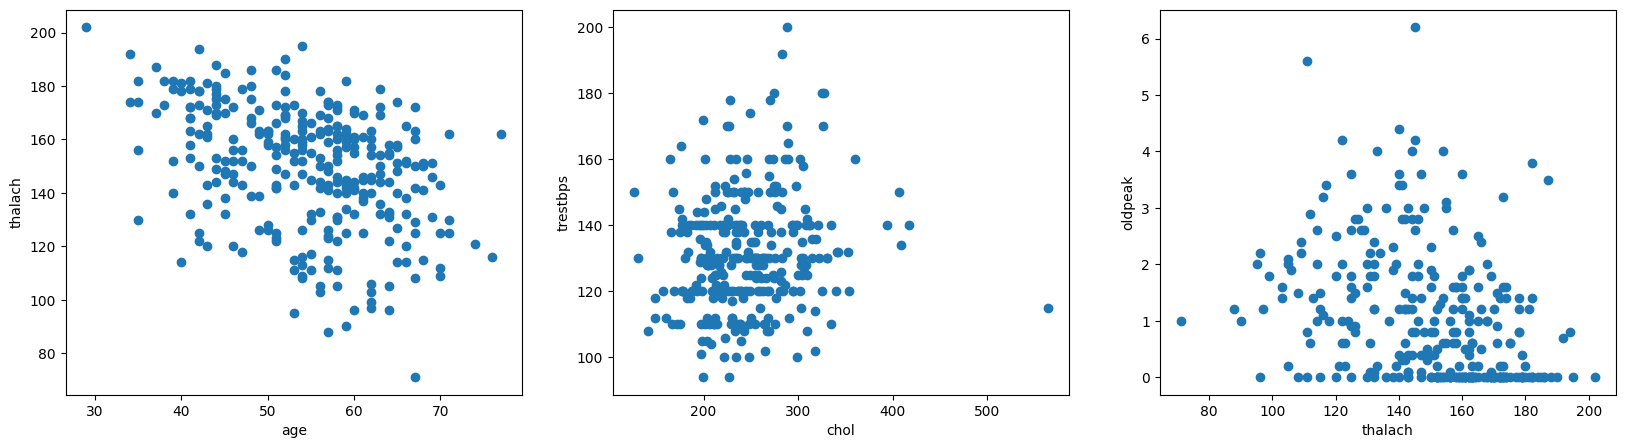

In [32]:
fig = plt.figure(figsize=(20, 5))  # Creamos una figura
ax1 = fig.add_subplot(131, projection='rectilinear')
ax2 = fig.add_subplot(132, projection='rectilinear')
ax3 = fig.add_subplot(133, projection='rectilinear')

ax1.scatter(pacientes['age'], pacientes['thalach'])
ax1.set_xlabel("age")
ax1.set_ylabel("thalach")

ax2.scatter(pacientes['chol'], pacientes['trestbps'])
ax2.set_xlabel("chol")
ax2.set_ylabel("trestbps")

ax3.scatter(pacientes['thalach'], pacientes['oldpeak'])
ax3.set_xlabel("thalach")
ax3.set_ylabel("oldpeak")

plt.show()

A diferencia de las viviendas, aquí no se ven grupos separados a simple vista: los pacientes forman una nube continua. Sí se aprecian algunas tendencias: la frecuencia cardíaca máxima (`thalach`) baja con la edad, y los pacientes con `oldpeak` alto suelen tener una frecuencia máxima más baja. También se ve que las variables tienen escalas muy distintas: el colesterol llega a más de 500, mientras que `oldpeak` no pasa de 7.

### 3. Preprocesado

Convertimos las 5 variables a una matriz, como hicimos con las viviendas.

Como k-means agrupa por distancias, si dejamos las variables como están, el colesterol (que varía en cientos) pesaría mucho más que `oldpeak` (que varía en unidades). Por eso las **escalamos**: a cada variable le restamos su media y la dividimos entre su desviación típica, de forma que todas quedan en una escala parecida. La media se calcula igual que los centroides en `actualiza_centr`:

In [33]:
pacientes_mat = pacientes[['age', 'trestbps', 'chol', 'thalach', 'oldpeak']].values

# Media y desviación típica de cada columna
media = np.sum(pacientes_mat, axis=0)/pacientes_mat.shape[0]
desviacion = np.sqrt(np.sum((pacientes_mat - media)**2, axis=0)/pacientes_mat.shape[0])

# Datos escalados
pacientes_esc = (pacientes_mat - media)/desviacion

### 4. Número de clusters (método del codo)

Usamos `KMeans`, porque nuestra función `k_medias` solo sirve para dos variables. Con `n_init=10` cada agrupamiento se repite con 10 inicializaciones distintas y se queda con la mejor, como hacía `k_medias_multi_ini`. Como coste usamos `inertia_ / len(pacientes)`, que mide la distancia cuadrática media de cada paciente a su centroide (a diferencia de `j()`, que no elevaba las distancias al cuadrado). Por eso, con $k=1$, el coste vale exactamente 5: al estar escaladas, cada una de las 5 variables aporta 1.

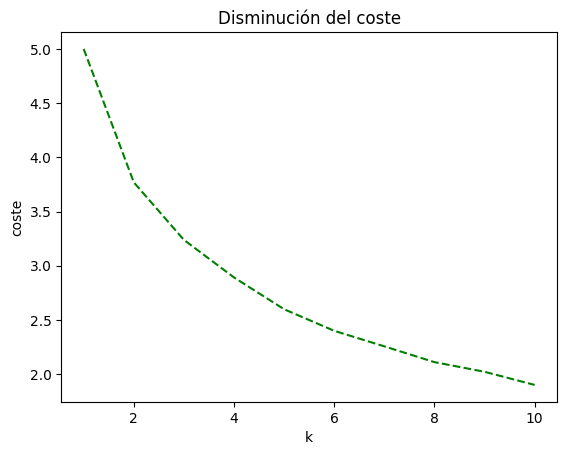

In [34]:
SEED_VALUE = 42

k_max = 10
custos_pacientes = []
for k in range(1, k_max+1):
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED_VALUE)
    np.random.seed(SEED_VALUE)
    agrupamento = model.fit(pacientes_esc)
    custos_pacientes.append(agrupamento.inertia_ / len(pacientes))

plt.plot(range(1, k_max+1), custos_pacientes, '--', color="green")
plt.title("Disminución del coste")
plt.xlabel("k")
plt.ylabel("coste")
plt.show()

In [35]:
custos_pacientes

[5.0,
 3.769199699365323,
 3.2385327056107607,
 2.8919224806990003,
 2.5987298399997028,
 2.3997293919021967,
 2.2563076058029994,
 2.110985440891099,
 2.0218129236466753,
 1.900561928064265]

El coste baja mucho al pasar de 1 a 2 clusters (de 5,0 a 3,8) y bastante de 2 a 3 (de 3,8 a 3,2), pero a partir de ahí cada cluster nuevo mejora mucho menos. El codo no es tan claro como en las viviendas, pero lo situamos en **$k=3$**.

### 5. Agrupamiento final

In [36]:
model = KMeans(n_clusters=3, n_init=10, random_state=SEED_VALUE)
np.random.seed(SEED_VALUE)
agrupamento_pacientes = model.fit(pacientes_esc)
clusters_pacientes = agrupamento_pacientes.labels_

# Centroides en las unidades originales (deshacemos el escalado)
# Columnas: age, trestbps, chol, thalach, oldpeak
centroides_pacientes = agrupamento_pacientes.cluster_centers_*desviacion + media
centroides_pacientes

array([[ 59.11627907, 127.13953488, 228.41860465, 125.75581395,
          1.87790698],
       [ 48.82993197, 125.16326531, 235.65306122, 164.05442177,
          0.43877551],
       [ 60.47142857, 150.98571429, 292.32857143, 148.57142857,
          1.27142857]])

In [37]:
# Número de pacientes en cada cluster
pacientes_por_cluster = []
for i in range(3):
    pacientes_por_cluster.append(np.sum(clusters_pacientes==i))
pacientes_por_cluster

[np.int64(86), np.int64(147), np.int64(70)]

### 6. Visualización del agrupamiento

Como hay 5 variables, representamos el agrupamiento por pares de variables, con los mismos pares de antes. Cada color es un cluster y las **x** son los centroides:

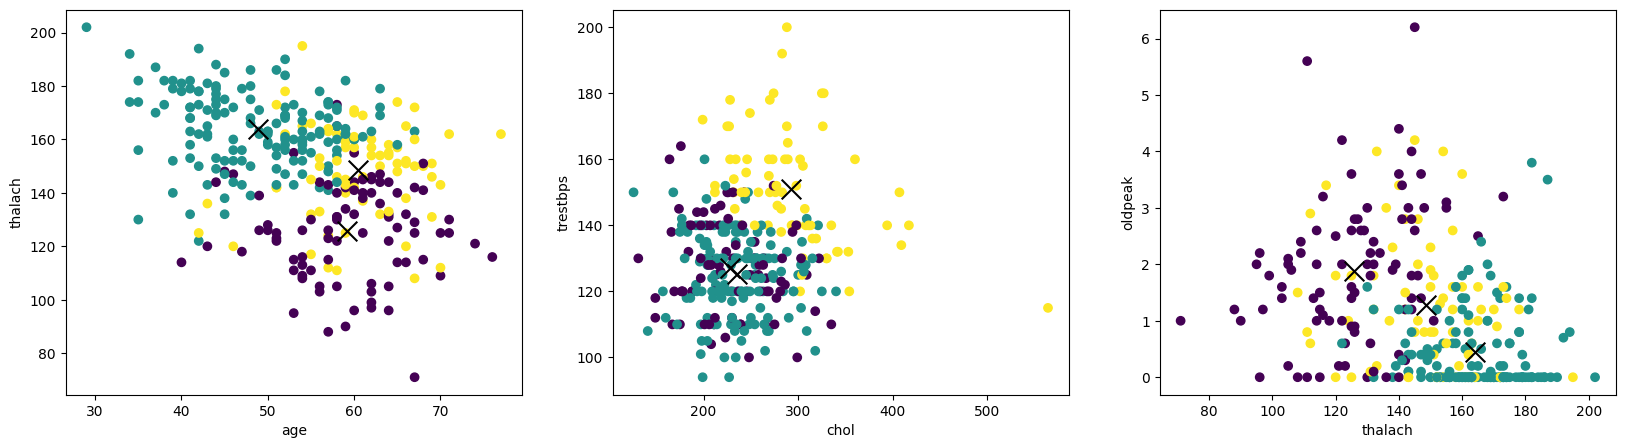

In [38]:
fig = plt.figure(figsize=(20, 5))  # Creamos una figura
ax1 = fig.add_subplot(131, projection='rectilinear')
ax2 = fig.add_subplot(132, projection='rectilinear')
ax3 = fig.add_subplot(133, projection='rectilinear')

ax1.scatter(pacientes['age'], pacientes['thalach'], c=clusters_pacientes)
ax1.scatter(centroides_pacientes[:, 0], centroides_pacientes[:, 3], s=200, marker='x', color='black')
ax1.set_xlabel("age")
ax1.set_ylabel("thalach")

ax2.scatter(pacientes['chol'], pacientes['trestbps'], c=clusters_pacientes)
ax2.scatter(centroides_pacientes[:, 2], centroides_pacientes[:, 1], s=200, marker='x', color='black')
ax2.set_xlabel("chol")
ax2.set_ylabel("trestbps")

ax3.scatter(pacientes['thalach'], pacientes['oldpeak'], c=clusters_pacientes)
ax3.scatter(centroides_pacientes[:, 3], centroides_pacientes[:, 4], s=200, marker='x', color='black')
ax3.set_xlabel("thalach")
ax3.set_ylabel("oldpeak")

plt.show()

### 7. Interpretación de los clusters

Viendo los centroides y las gráficas, los tres clusters corresponden a tres tipos de paciente:

- Cluster 0 (morado, 86 pacientes): mala respuesta al esfuerzo. Son mayores (unos 59 años de media), alcanzan una frecuencia cardíaca máxima baja (alrededor de 126) y tienen el `oldpeak` más alto (aproximadamente 1,9), aunque su presión y su colesterol son normales. Su corazón responde peor al esfuerzo, así que es el grupo de mayor riesgo.
- Cluster 1 (verde, 147 pacientes): jóvenes en buena forma. Son los más jóvenes (unos 49 años de media), con la frecuencia cardíaca máxima más alta (alrededor de 164) y casi sin alteración en el electrocardiograma (`oldpeak` de aproximadamente 0,4). Es el grupo más numeroso y el de menor riesgo.
- Cluster 2 (amarillo, 70 pacientes): presión y colesterol altos. También son mayores (unos 60 años de media), pero lo que los distingue es que tienen la presión (alrededor de 151) y el colesterol (alrededor de 292) más altos. Su respuesta al esfuerzo es intermedia.

En las gráficas se ve que la edad y la frecuencia cardíaca máxima (primera gráfica) separan el cluster 1 del 0, y que el colesterol y la presión (segunda gráfica) separan el cluster 2. Aun así, los grupos se solapan bastante, porque los pacientes no forman nubes separadas como las viviendas. Además, como no tenemos etiquetas, no podemos saber qué pacientes están realmente enfermos: los clusters describen perfiles de pacientes, no diagnósticos.

**************************************************************